# Module G: Edit-Process Analysis

**What this module does:** it studies *how* people edit an LLM draft, not only what the final text looks like.

**Data:** the keystroke logs released with the original study (`ctbaumler/personal_style_postedit`, folder `logs/`; the `logs/` folder in our project repo holds identical copies). Every task has an `edits` field that records each insertion, deletion and replacement with its position and a timestamp: 324 post-edited tasks from all 81 participants. We replay these events to reconstruct the full editing process, so no new data collection is needed.

**Four questions:**
1. **Speed:** how long before the first edit, and how fast do people edit?
2. **Order:** do people edit top to bottom? Are the sentences Module C flags as AI fixed first?
3. **Prediction:** does the editing process predict how much closer the text gets to the person's own style, better than the amount of editing alone?
4. **Personal style:** do people edit in a consistent way from one task to the next?

Each question ends with a short **Conclusion** in plain words, and the notebook ends with an overall summary. Section 7c is a cross-check that uses Module E's answer key and classifier to test whether the main results hold with a second, independent measurement.

## 1. Setup

In [2]:
import os, re, json, glob, subprocess, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
import nltk
from nltk.tokenize import sent_tokenize
import statsmodels.formula.api as smf
from sklearn.linear_model import Ridge
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

warnings.filterwarnings("ignore")
nltk.download("punkt_tab", quiet=True)

OUT_DIR = "task_G_results"
os.makedirs(OUT_DIR, exist_ok=True)

# the project repo has the 81 logs, A2's results and the split lists
# (GIT_LFS_SKIP_SMUDGE skips the 500 MB model, we only need it in section 6)
def find_root():
    """Locate the project folder (the one that contains logs/) without cloning.
    Works if Jupyter was started in the repo root, in a subfolder of the repo,
    or in a folder that has MLProject/ inside it."""
    here = os.path.abspath(".")
    for cand in (here, os.path.join(here, "MLProject")):
        if os.path.isdir(os.path.join(cand, "logs")):
            return cand
    p = here
    while os.path.dirname(p) != p:                 # walk up the parent folders
        p = os.path.dirname(p)
        if os.path.isdir(os.path.join(p, "logs")):
            return p
    return None

ROOT = find_root()
if ROOT is not None:
    print("yayyy")

yayyy


In [3]:
if ROOT is None:                                   # last resort: not found anywhere, so clone
    subprocess.run(["git", "clone", "https://github.com/harshitaagrawalIT123/MLProject"],
                   env={**os.environ, "GIT_LFS_SKIP_SMUDGE": "1"})
    ROOT = os.path.abspath("MLProject")
print("project root:", ROOT)

project root: D:\IIT BH in D\ML\Project\task_G\MLProject


## 2. Load the post-edited tasks
Only the **treatment** tasks (the person edited an LLM draft). Each task has the draft, the final text, and the list of edit events. Every event has a type (insert / delete / replace), a position in the text, the characters added or removed, and a timestamp.

In [4]:
rows = []
for file in glob.glob(os.path.join(ROOT, "logs", "*.json")):
    data = json.load(open(file, encoding="utf-8"))
    pid = data["user_info"]["id"]
    for k, task in data["responses"].items():
        if "scenario" not in task or task["model_generation_shown"] != 1:
            continue
        rows.append({"pid": pid, "k": int(k), "scenario": task["scenario"],
                     "draft": task["model_generation"], "final": task["final_version"],
                     "edits": task["edits"],
                     "t_details": task["submit_details_time"],      # when the person submitted their details (draft appears)
                     "t_submit": task["submit_final_text_time"]})   # when they submitted the final text
T = pd.DataFrame(rows)
print(len(T), "post-edited tasks from", T["pid"].nunique(), "participants")

324 post-edited tasks from 81 participants


## 3. Replay the edits
We start from the LLM draft and apply every event in order. This rebuilds the document **at every moment**, not only the final text.

While replaying we also track, for every character, whether it is **original draft text** or **new text the person typed**. That lets us say *which draft sentence* each edit touched and *when*. A sentence counts as touched if the person deleted or replaced some of its original text, or typed inside it. New text added between sentences is not counted as touching a sentence.

**Check:** the replayed text must equal the real final text. If it does, the log is trustworthy.

In [5]:
def same_text(a, b):
    return re.sub(r"\s+", " ", a).strip() == re.sub(r"\s+", " ", b).strip()

def replay_task(task):
    draft = task["draft"]

    # split the draft into sentences and remember where each one sits
    spans, start = [], 0
    for s in sent_tokenize(draft):
        a = draft.find(s, start)
        spans.append((a, a + len(s)))
        start = a + len(s)
    sent_of = {}                                   # character position in the draft -> sentence number
    for i, (a, b) in enumerate(spans):
        for c in range(a, b):
            sent_of[c] = i

    text = draft
    origin = list(range(len(draft)))               # per current character: its position in the draft, or -1 if the person typed it
    first_touch, order = {}, []                    # sentence -> time it was first touched; the sequence of touched sentences

    def touch(i, ts):
        if i not in first_touch:
            first_touch[i] = ts
        if not order or order[-1] != i:
            order.append(i)

    for e in task["edits"]:
        p, ts = e["position"], float(e["timestamp"])
        n_removed = len(e["removed"])
        if e["type"] == "insert":
            left  = origin[p - 1] if p > 0 else -1
            right = origin[p] if p < len(origin) else -1
            if left >= 0 and right >= 0 and sent_of.get(left) is not None and sent_of.get(left) == sent_of.get(right):
                touch(sent_of[left], ts)           # typed inside an existing sentence
            origin[p:p] = [-1] * len(e["added"])
            text = text[:p] + e["added"] + text[p:]
        else:                                      # delete or replace
            for o in origin[p:p + n_removed]:
                if o >= 0 and o in sent_of:
                    touch(sent_of[o], ts)          # removed some original draft text
            origin[p:p + n_removed] = [-1] * len(e["added"])
            text = text[:p] + e["added"] + text[p + n_removed:]

    if text == task["final"]:
        status = "exact"
    elif same_text(text, task["final"]):
        status = "same except spaces"
    else:
        status = "mismatch"
    return status, spans, first_touch, order

results = [replay_task(t) for _, t in T.iterrows()]
T["status"] = [r[0] for r in results]
print(T["status"].value_counts())
print("\ntasks with no edit events:", (T["edits"].apply(len) == 0).sum(), "(almost all of these kept the draft unchanged)")

status
exact                 296
same except spaces     26
mismatch                2
Name: count, dtype: int64

tasks with no edit events: 44 (almost all of these kept the draft unchanged)


## 4. Process features for every task
For each task that has edits and replays correctly:
- **time to first edit:** seconds between the draft appearing and the first event
- **active time:** seconds from the first event to the last
- **edit speed:** characters inserted plus deleted, per minute of active time
- **bursts:** a burst is a run of events with pauses under 2 seconds. Many bursts means many separate editing episodes
- **longest pause:** the longest gap between two events
- **share of sentences touched**, and **returns:** how often the person came back to a sentence they had already edited after working elsewhere

In [6]:
feat, sent_rows = [], []
for (_, t), (status, spans, first_touch, order) in zip(T.iterrows(), results):
    ev = t["edits"]
    if len(ev) == 0 or status == "mismatch":
        continue
    ts = np.array([float(e["timestamp"]) for e in ev])
    gaps = np.diff(ts)
    inserted = sum(len(e["added"]) for e in ev)
    deleted  = sum(len(e["removed"]) for e in ev)
    active = ts[-1] - ts[0]
    feat.append({"pid": t["pid"], "k": t["k"], "n_events": len(ev),
                 "time_to_first_edit": ts[0] - t["t_details"],
                 "active_time": active, "total_time": t["t_submit"] - t["t_details"],
                 "chars_changed": inserted + deleted,
                 "speed_per_min": (inserted + deleted) / (max(active, 5) / 60),
                 "n_bursts": 1 + int((gaps >= 2).sum()),
                 "longest_pause": gaps.max() if len(gaps) else 0,
                 "share_touched": len(first_touch) / len(spans),
                 "n_returns": len(order) - len(set(order))})
    sentences = sent_tokenize(t["draft"])
    for i in range(len(spans)):
        sent_rows.append({"pid": t["pid"], "k": t["k"], "sent_idx": i, "n_sents": len(spans),
                          "text": t["draft"][spans[i][0]:spans[i][1]],
                          "touched": int(i in first_touch),
                          "first_touch": first_touch[i] - ts[0] if i in first_touch else np.nan})

F = pd.DataFrame(feat)
S = pd.DataFrame(sent_rows)
print(len(F), "edited tasks from", F["pid"].nunique(), "participants")
print("\n", F[["n_events", "time_to_first_edit", "active_time", "total_time", "speed_per_min", "n_bursts", "longest_pause", "share_touched", "n_returns"]]
      .describe().T[["25%", "50%", "75%", "max"]].round(1))
print("\ntasks where the first edit is logged BEFORE the draft appeared:", (F["time_to_first_edit"] < 0).sum(), "(clock anomaly, excluded from timing results)")

280 edited tasks from 81 participants

                       25%    50%    75%     max
n_events             45.8  102.0  200.2  2569.0
time_to_first_edit   17.8   37.1   68.2   498.2
active_time          50.5   99.8  175.5  1243.1
total_time          130.8  155.9  258.9  1289.0
speed_per_min        50.5   82.9  126.4  5839.3
n_bursts              4.0    7.0   12.0    88.0
longest_pause        10.3   22.7   40.8   316.6
share_touched         0.1    0.2    0.4     1.0
n_returns             0.0    0.0    0.0    15.0

tasks where the first edit is logged BEFORE the draft appeared: 17 (clock anomaly, excluded from timing results)


## 5. Question 1: how fast do people edit?
Median time before the first edit, how long they edit for, and how fast. The 'before the draft appeared' anomalies are left out of the time-to-first-edit numbers.

time to first edit : median 41 s  (middle half 21 to 70 s)
active editing time: median 100 s  (middle half 50 to 175 s)
edit speed         : median 83 characters per minute
bursts per task    : median 7
sentences touched  : median 22% of the draft
returns to a sentence already edited: 12% of tasks


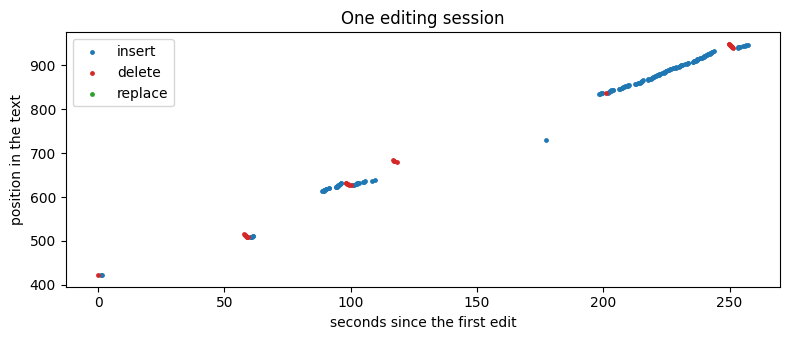

In [7]:
ok = F[F["time_to_first_edit"] >= 0]
print(f"time to first edit : median {ok.time_to_first_edit.median():.0f} s  (middle half {ok.time_to_first_edit.quantile(.25):.0f} to {ok.time_to_first_edit.quantile(.75):.0f} s)")
print(f"active editing time: median {F.active_time.median():.0f} s  (middle half {F.active_time.quantile(.25):.0f} to {F.active_time.quantile(.75):.0f} s)")
print(f"edit speed         : median {F.speed_per_min.median():.0f} characters per minute")
print(f"bursts per task    : median {F.n_bursts.median():.0f}")
print(f"sentences touched  : median {100 * F.share_touched.median():.0f}% of the draft")
print(f"returns to a sentence already edited: {(F.n_returns > 0).mean():.0%} of tasks")

# one example: when and where in the text each edit happened
example = F[(F.n_events > 150) & (F.n_events < 300)].iloc[0]
tk = T[(T.pid == example.pid) & (T.k == example.k)].iloc[0]
ev = pd.DataFrame(tk["edits"]); ev["t"] = ev["timestamp"].astype(float) - ev["timestamp"].astype(float).iloc[0]
plt.figure(figsize=(8, 3.5))
for typ, color in [("insert", "tab:blue"), ("delete", "tab:red"), ("replace", "tab:green")]:
    d = ev[ev.type == typ]
    plt.scatter(d.t, d.position, s=6, color=color, label=typ)
plt.xlabel("seconds since the first edit"); plt.ylabel("position in the text"); plt.legend(); plt.title("One editing session")
plt.tight_layout(); plt.savefig(f"{OUT_DIR}/fig_trajectory.png", dpi=150); plt.show()

### Conclusion: Question 1 (speed)
**A typical edit session is short and light.**
- People wait about **41 seconds** (middle half: 21 to 70 s) before changing anything, then edit for about **100 seconds** (middle half: 50 to 175 s). A whole edited task takes about 2.5 minutes.
- They edit at about **83 characters per minute**, in about **7 short bursts**.
- They touch only about **22% of the sentences**, roughly 1 in 5. Only **12%** of tasks go back to a sentence that was already edited, so most people make a single pass.
- In **44 of the 324 tasks** (14%) no edits were recorded, almost always because the person kept the draft unchanged.

*Note: this is a description of a typical session, not a test. The time before the first edit includes reading the draft and deciding what to change, and edit speed depends on how much needed fixing. Draft length was not controlled, and the logs cannot separate reading time from editing time. The share of sentences touched is the most robust number here, because it is a proportion of the draft.*

*(17 tasks have a clock anomaly and are left out of the time-to-first-edit number.)*


## 6. Question 2: in what order do people edit?
**(a) Top to bottom?** For each task with at least 3 touched sentences, we compute the Spearman correlation between a sentence's position in the draft and the time it was first touched. A value above 0 means the person works down the text in reading order. Tasks are averaged per person first, because one person wrote several.

In [8]:
rows = []
for (pid, k), g in S[S.touched == 1].groupby(["pid", "k"]):
    if len(g) >= 3:
        rows.append({"pid": pid, "k": k, "rho": stats.spearmanr(g.sent_idx, g.first_touch)[0], "n_touched": len(g)})
R = pd.DataFrame(rows).dropna()
per_person = R.groupby("pid")["rho"].mean()
w = stats.wilcoxon(per_person)

print(len(R), "tasks with at least 3 touched sentences,", len(per_person), "participants")
print("median correlation between sentence position and edit time:", round(R.rho.median(), 2))
print("share of tasks where the person works top to bottom (rho > 0):", f"{(R.rho > 0).mean():.0%}")
print("per-person averages vs 0 (Wilcoxon):", f"p = {w.pvalue:.2g}")

# for comparison: what would a person who edits in random order get?
rng = np.random.default_rng(0)
random_rho = [stats.spearmanr(np.arange(n), rng.permutation(n))[0] for n in R.n_touched]
print("for comparison, editing in random order would give: median", round(np.nanmedian(random_rho), 2),
      "and", f"{(np.array(random_rho) > 0).mean():.0%}", "of tasks above 0")

115 tasks with at least 3 touched sentences, 48 participants
median correlation between sentence position and edit time: 1.0
share of tasks where the person works top to bottom (rho > 0): 90%
per-person averages vs 0 (Wilcoxon): p = 3.4e-08
for comparison, editing in random order would give: median -0.1 and 43% of tasks above 0


### Conclusion: Question 2(a), order
**Yes. People edit from top to bottom, in reading order.**
- Across the 115 tasks where at least 3 sentences were touched (48 people), the median correlation between a sentence's position and the time it was edited is **1.0**, which is a perfect top-to-bottom order. **90%** of tasks are above 0.
- If people edited in random order, the median would be about **-0.1**, with only 43% of tasks above 0.
- The result holds across people (p = 3.4e-08), not just in a few tasks.
- The "One editing session" plot in Section 5 is one example of the same pattern: the edits climb steadily down the text as time passes.

**(b) Are the sentences Module C flags as AI fixed first?** We score every draft sentence with Module C's classifier, then ask two things inside each document: are high-AI sentences *more likely to be touched*, and among touched sentences, are high-AI ones *touched earlier*? Sentence position is controlled, because people also tend to edit in reading order.

**Only the 36 validation and test participants are used here.** Module C trained on the other 45 participants' drafts, so it has already seen those exact sentences and would give them inflated AI scores. Set `USE_MODULE_C = False` to skip this part.

**The score used.** Module C's probability is almost constant on LLM drafts (97% of sentences score above 0.95), so it cannot rank sentences. We therefore use the raw logit (evidence for "AI" minus evidence for "human") and standardize it within each document. This gives, for every sentence, how AI-looking it is compared with the rest of its own draft.


In [9]:
USE_MODULE_C = True

# your copy of the model goes first in this list if it is somewhere else
MODEL_CANDIDATES = [
    "D:/IIT BH in D/ML/Project/Part E/roberta_ai_human_model",   # your local full copy
    "/content/drive/MyDrive/task_C/roberta_ai_human_model",
    os.path.join(ROOT, "task_C", "roberta_ai_human_model"),
]

def has_model(folder):
    f = os.path.join(folder, "model.safetensors")
    return os.path.exists(f) and os.path.getsize(f) > 400e6

if USE_MODULE_C:
    import torch
    from transformers import AutoTokenizer, AutoModelForSequenceClassification
    MODEL_DIR = next((p for p in MODEL_CANDIDATES if has_model(p)), None)
    assert MODEL_DIR is not None, "Model not found. Add its folder to MODEL_CANDIDATES (see the E notebook), or set USE_MODULE_C = False."
    device = "cuda" if torch.cuda.is_available() else "cpu"
    try:
        tok = AutoTokenizer.from_pretrained(MODEL_DIR)
    except Exception:
        tok = AutoTokenizer.from_pretrained("roberta-base")
    clf = AutoModelForSequenceClassification.from_pretrained(MODEL_DIR).to(device).eval()

    def ai_prob(sentences):
        out = []
        for i in range(0, len(sentences), 16):
            enc = tok(sentences[i:i + 16], truncation=True, max_length=128, padding=True, return_tensors="pt").to(device)
            with torch.no_grad():
                out += torch.softmax(clf(**enc).logits, dim=1)[:, 1].tolist()
        return out
    print("using model folder:", MODEL_DIR)

using model folder: D:/IIT BH in D/ML/Project/Part E/roberta_ai_human_model


In [10]:
if USE_MODULE_C:
    # --- 1. raw logit score instead of the saturated probability ---
    def ai_logit(sentences):
        out = []
        for i in range(0, len(sentences), 16):
            enc = tok(sentences[i:i + 16], truncation=True, max_length=128,
                      padding=True, return_tensors="pt").to(device)
            with torch.no_grad():
                lg = clf(**enc).logits
            out += (lg[:, 1] - lg[:, 0]).tolist()          # evidence for "AI" minus evidence for "human"
        return out

    # same unseen participants as before (36 people)
    from sklearn.model_selection import GroupShuffleSplit
    def get_ids(path):
        return [re.split(r"[\\/]", l.strip())[-1].replace(".json", "") for l in open(path, encoding="utf-8") if l.strip()]
    train_ids = get_ids(os.path.join(ROOT, "task_A3", "train_files.txt"))
    test_ids  = get_ids(os.path.join(ROOT, "task_A3", "test_files.txt"))
    groups = np.array(train_ids)
    _, val_idx = next(GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=42).split(groups, groups=groups))
    unseen = set(groups[val_idx]) | set(test_ids)

    U = S[S.pid.isin(unseen)].copy()
    U["ai_prob"]  = ai_prob(U["text"].tolist())
    U["ai_logit"] = ai_logit(U["text"].tolist())
    print(U.pid.nunique(), "participants,", U.groupby(["pid", "k"]).ngroups, "edited documents,", len(U), "sentences")

    # --- 2. does the logit keep more spread between sentences than the probability? ---
    doc = U.groupby(["pid", "k"])
    print("\nshare of sentences with AI probability > 0.95:", f"{(U.ai_prob > 0.95).mean():.0%}")
    print("average spread INSIDE a document (std):  probability =", round(doc.ai_prob.std().mean(), 3),
          "| logit =", round(doc.ai_logit.std().mean(), 2))

    # --- 3. score each sentence relative to its own document ---
    U["ai_z"]  = (U.ai_logit - doc.ai_logit.transform("mean")) / doc.ai_logit.transform("std")   # "how AI vs the rest of this draft"
    U["pos_c"] = U.sent_idx / (U.n_sents - 1) - 0.5
    U["touched_c"] = U.touched - doc.touched.transform("mean")
    U = U.dropna(subset=["ai_z"])                                  # drops documents where all sentences score the same

    print("\nmean AI logit  touched:", round(U[U.touched == 1].ai_logit.mean(), 2),
          "| untouched:", round(U[U.touched == 0].ai_logit.mean(), 2))

    m1 = smf.ols("touched_c ~ ai_z + pos_c", data=U).fit(cov_type="cluster", cov_kwds={"groups": U["pid"]})
    print(f"\n(1) more likely to be touched if it looks MORE AI than the rest of its draft?\n"
          f"    effect of +1 SD within the document = {m1.params['ai_z']:+.3f}  (p = {m1.pvalues['ai_z']:.3g})   [{U.groupby(['pid','k']).ngroups} documents]")

    V = U[U.touched == 1].copy()
    V["n_touched"] = V.groupby(["pid", "k"]).sent_idx.transform("count")
    V = V[V.n_touched >= 3].copy()
    V["rank"]   = V.groupby(["pid", "k"]).first_touch.rank(pct=True)
    V["rank_c"] = V["rank"] - V.groupby(["pid", "k"])["rank"].transform("mean")
    m2 = smf.ols("rank_c ~ ai_z + pos_c", data=V).fit(cov_type="cluster", cov_kwds={"groups": V["pid"]})
    print(f"(2) touched EARLIER if it looks more AI than the rest of its draft?\n"
          f"    effect of +1 SD on touch order = {m2.params['ai_z']:+.3f}  (p = {m2.pvalues['ai_z']:.3g})   [{V.groupby(['pid','k']).ngroups} documents]")
    print("    (negative = AI-looking sentences are touched earlier; position is controlled)")

    # --- 4. effect size with a 95% interval, so a null is reported with its precision ---
    ci1 = m1.conf_int().loc["ai_z"].values
    ci2 = m2.conf_int().loc["ai_z"].values
    print(f"\n95% CI (1): [{ci1[0]:+.3f}, {ci1[1]:+.3f}]   95% CI (2): [{ci2[0]:+.3f}, {ci2[1]:+.3f}]")

36 participants, 120 edited documents, 1182 sentences

share of sentences with AI probability > 0.95: 97%
average spread INSIDE a document (std):  probability = 0.062 | logit = 1.28

mean AI logit  touched: 7.62 | untouched: 7.51

(1) more likely to be touched if it looks MORE AI than the rest of its draft?
    effect of +1 SD within the document = +0.013  (p = 0.232)   [120 documents]
(2) touched EARLIER if it looks more AI than the rest of its draft?
    effect of +1 SD on touch order = +0.002  (p = 0.923)   [42 documents]
    (negative = AI-looking sentences are touched earlier; position is controlled)

95% CI (1): [-0.008, +0.034]   95% CI (2): [-0.029, +0.032]


### Conclusion: Question 2(b), are AI-flagged sentences fixed first?
**No. Module C's flags do not predict which sentences people edit, or when.**
- Module C's probability is saturated: 97% of draft sentences score above 0.95. To get around this we used the raw logit and compared each sentence with the rest of *its own* draft, with sentence position controlled.
- A sentence that looks one standard deviation more "AI" than the rest of its draft is not touched more often (effect +0.013, 95% CI [-0.008, +0.034], 120 documents) and not touched earlier (effect +0.002, 95% CI [-0.029, +0.032], 42 documents).
- The intervals are narrow: any effect larger than about 3 percentage points in touch probability, or about 3 percentile points in touch order, per standard deviation is ruled out.
- So Module C's score, even when ranked within a draft, does not show where people will edit. Together with 2(a), people simply work down the text.

*(Only the 36 people Module C never trained on are used: 120 documents for "touched or not", 42 for "touched earlier".)*


## 7. Question 3: does the process predict style recovery better than the amount of editing?
**Outcome:** how much closer the final text is to the person's own writing than the original draft was (`delta_similarity` from Module A2, LUAR similarity after minus before).

**Models** (all use the same cross-validation, where no person is ever in both the training and test part):
- **A:** edit amount (WER) only
- **B:** edit count only (number of keystroke events), the 'edit count alone' baseline from the proposal
- **C:** process features only
- **D:** edit amount plus process features
- **E:** edit count plus process features

Tasks with no edits (draft kept unchanged) and the 17 tasks with the timing anomaly are left out.

In [11]:
A2 = pd.read_csv(os.path.join(ROOT, "task_A2", "A2_response_level.csv")).rename(columns={"participant_id": "pid", "response_id": "k"})
M = F[F.time_to_first_edit >= 0].merge(A2[["pid", "k", "WER", "delta_similarity"]], on=["pid", "k"])
for c in ["n_events", "time_to_first_edit", "active_time", "speed_per_min", "n_bursts"]:
    M["log_" + c] = np.log1p(M[c])
print(len(M), "tasks,", M.pid.nunique(), "participants")

process = ["log_time_to_first_edit", "log_active_time", "log_speed_per_min", "log_n_bursts", "share_touched", "n_returns"]
models = {"A  edit amount (WER)":      ["WER"],
          "B  edit count":             ["log_n_events"],
          "C  process only":           process,
          "D  WER + process":          ["WER"] + process,
          "E  edit count + process":   ["log_n_events"] + process}

y = M["delta_similarity"].values
people = M.pid.unique()
rng = np.random.default_rng(0)
pred = {name: [] for name in models}

for rep in range(30):                                   # repeat with different random groupings of people
    fold_of = {p: i % 5 for i, p in enumerate(rng.permutation(people))}
    folds = M.pid.map(fold_of).values
    for name, cols in models.items():
        p = np.zeros(len(M))
        for f in range(5):
            train, test = folds != f, folds == f
            model = make_pipeline(StandardScaler(), Ridge(alpha=10.0)).fit(M.loc[train, cols].values, y[train])
            p[test] = model.predict(M.loc[test, cols].values)
        pred[name].append(p)

pred = {name: np.mean(v, axis=0) for name, v in pred.items()}
table = pd.DataFrame({"model": list(models),
                      "R2_out_of_sample": [1 - ((y - pred[n]) ** 2).sum() / ((y - y.mean()) ** 2).sum() for n in models]})
print(table.round(3).to_string(index=False))
table.round(3).to_csv(f"{OUT_DIR}/model_comparison.csv", index=False)

263 tasks, 77 participants
                  model  R2_out_of_sample
   A  edit amount (WER)             0.329
          B  edit count             0.266
        C  process only             0.213
       D  WER + process             0.265
E  edit count + process             0.242


D vs A:  mean change in squared error -1.79e-04   95% CI [-4.75e-04, +2.28e-05]  -> no clear difference
E vs B:  mean change in squared error -6.70e-05   95% CI [-3.18e-04, +1.45e-04]  -> no clear difference
C vs B:  mean change in squared error -1.49e-04   95% CI [-4.41e-04, +9.46e-05]  -> no clear difference
C vs A:  mean change in squared error -3.26e-04   95% CI [-5.51e-04, -1.20e-04]  -> worse


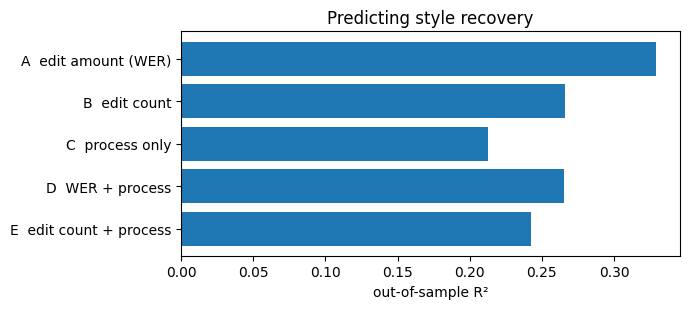

In [12]:
def gain_over(base, new, n=2000):
    # how much smaller is the squared error of `new` than `base`? (positive = new is better)
    d = (y - pred[base]) ** 2 - (y - pred[new]) ** 2
    per_person = [d[(M.pid == p).values] for p in people]
    r = np.random.default_rng(1)
    boots = [np.concatenate([per_person[i] for i in r.integers(0, len(people), len(people))]).mean() for _ in range(n)]
    lo, hi = np.percentile(boots, [2.5, 97.5])
    verdict = "better" if lo > 0 else ("worse" if hi < 0 else "no clear difference")
    print(f"{new[:1]} vs {base[:1]}:  mean change in squared error {d.mean():+.2e}   95% CI [{lo:+.2e}, {hi:+.2e}]  -> {verdict}")

gain_over("A  edit amount (WER)", "D  WER + process")          # does the process add to edit amount?
gain_over("B  edit count", "E  edit count + process")          # the proposal's question: process vs edit count alone
gain_over("B  edit count", "C  process only")
gain_over("A  edit amount (WER)", "C  process only")

plt.figure(figsize=(7, 3.2))
plt.barh(table["model"][::-1], table["R2_out_of_sample"][::-1], color="tab:blue")
plt.xlabel("out-of-sample R²"); plt.title("Predicting style recovery"); plt.tight_layout()
plt.savefig(f"{OUT_DIR}/fig_model_comparison.png", dpi=150); plt.show()

In [13]:
# Direction check: does editing move the text CLOSER to the person's own style, and does more editing mean a bigger move?
d = M["delta_similarity"]
per_person = M.groupby("pid")["delta_similarity"].mean()          # one number per person, so heavy editors do not dominate
w = stats.wilcoxon(per_person)
print(f"tasks: {len(M)}, people: {M.pid.nunique()}")
print(f"mean delta_similarity: {d.mean():+.4f}   median: {d.median():+.4f}")
print(f"share of tasks that moved closer (delta > 0): {(d > 0).mean():.0%}")
print(f"per-person averages vs 0 (Wilcoxon): p = {w.pvalue:.2g};  share of people closer on average: {(per_person > 0).mean():.0%}")

# bootstrap CI for the mean, resampling whole people
by_person = {p: g["delta_similarity"].values for p, g in M.groupby("pid")}
keys = list(by_person); r = np.random.default_rng(0)
boots = [np.concatenate([by_person[keys[i]] for i in r.integers(0, len(keys), len(keys))]).mean() for _ in range(1000)]
print(f"95% CI for the mean change (resampling people): [{np.percentile(boots, 2.5):+.4f}, {np.percentile(boots, 97.5):+.4f}]")

# direction: does more editing mean a bigger change?
rho, p = stats.spearmanr(M["WER"], M["delta_similarity"])
print(f"\nmore editing vs change in similarity: Spearman rho = {rho:+.2f} (p = {p:.2g})")
sl = smf.ols("delta_similarity ~ WER", data=M).fit(cov_type="cluster", cov_kwds={"groups": M["pid"]})
print(f"slope: {sl.params['WER']:+.4f} per +1.0 WER  (p = {sl.pvalues['WER']:.3g})")

level = pd.qcut(M["WER"].rank(method="first"), 3, labels=["light", "medium", "heavy"])
print("\nlight vs heavy editors:")
print(M.groupby(level)["delta_similarity"].agg(mean="mean", share_closer=lambda x: (x > 0).mean(), n="count").round(3))

# how much do the process features overlap with edit amount?
print("\ncorrelation of each process feature with edit amount (WER):")
print(M[process + ["WER"]].corr()["WER"].drop("WER").round(2).to_string())


tasks: 263, people: 77
mean delta_similarity: +0.0430   median: +0.0284
share of tasks that moved closer (delta > 0): 81%
per-person averages vs 0 (Wilcoxon): p = 3.1e-13;  share of people closer on average: 95%
95% CI for the mean change (resampling people): [+0.0340, +0.0521]

more editing vs change in similarity: Spearman rho = +0.53 (p = 1.3e-20)
slope: +0.1249 per +1.0 WER  (p = 1.96e-10)

light vs heavy editors:
         mean  share_closer   n
WER                            
light   0.015         0.636  88
medium  0.035         0.897  87
heavy   0.078         0.909  88

correlation of each process feature with edit amount (WER):
log_time_to_first_edit   -0.21
log_active_time           0.52
log_speed_per_min         0.58
log_n_bursts              0.58
share_touched             0.70
n_returns                 0.34


### Conclusion: Question 3, does the process beat the amount of editing?
**No. How much people edit predicts style recovery best. How they edit adds nothing measurable.**
- Edit amount (WER) alone explains **33%** of the variation in style recovery (R² = 0.329). That is more than edit count (0.266), process features alone (0.213), or any combination.
- Adding process features to edit amount does not help (D vs A: no clear difference, and the estimate is even slightly worse). Adding them to edit count does not help either (E vs B). Process features alone are clearly worse than edit amount (C vs A: worse) and about as good as edit count (C vs B: no clear difference).
- In simple words: *how much* someone rewrites is the best predictor of how much the similarity to their own style changes. *When, how fast, and in how many bursts* they do it adds no extra information. R² alone does not show the direction of the change; whether editing moves the text *closer* on average, and whether more editing means a bigger move, is checked in the direction cell above.
- This is partly expected, because edit amount and the similarity change are both computed from how much the text changed. The more informative number is that about **two thirds of the variation is still unexplained**, so *which* parts of the text people change probably matters more than how much or how fast.

*(Based on 263 tasks from 77 people. The outcome is A2's LUAR similarity change, which A3 found sensitive to setup, and process features overlap strongly with edit amount.)*


## 7b. Question 4: is editing a personal style?
Do people edit in a consistent way from one task to the next, or does it depend on the task? Each person has up to 4 edited tasks, so we can compare variation *between* people with variation *within* a person.

- **ICC (intraclass correlation):** the share of all variation that belongs to the person. 0 = tasks are unrelated to who wrote them, 1 = a person behaves the same every time. Rule of thumb used here: below 0.25 weak, 0.25 to 0.5 moderate, 0.5 and above strong. The average of each scenario (wedding, apology, ...) is removed first, so differences between task types don't count as personal style.
- **History gain:** predict each task from the same person's *other* tasks, and compare with predicting it from the group average. 0 = no better than the group average, 0.4 = 40% smaller error.
- Both come with 95% intervals from resampling people. Only people with at least 2 edited tasks are used.

                 behaviour  people  ICC  CI_low  CI_high strength  history_gain  gain_low  gain_high
         edit amount (WER)      77 0.54    0.31     0.74   strong          0.41      0.13       0.70
share of sentences touched      77 0.58    0.40     0.71   strong          0.47      0.24       0.65
       edit events (count)      77 0.57    0.43     0.67   strong          0.37      0.14       0.54
        time to first edit      73 0.32    0.16     0.47 moderate          0.06     -0.17       0.27
       active editing time      77 0.46    0.31     0.58 moderate          0.21     -0.00       0.42
                edit speed      77 0.53    0.23     0.72   strong          0.34     -0.08       0.61
            editing bursts      77 0.54    0.40     0.64   strong          0.39      0.21       0.55


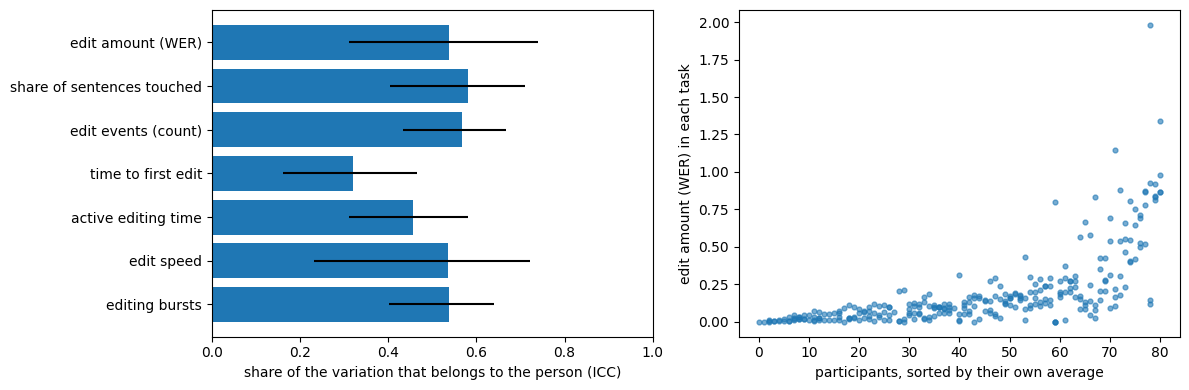

In [14]:
# one row per edited task, with the behaviours we want to test
Q4 = (F.merge(A2[["pid", "k", "WER"]], on=["pid", "k"])
        .merge(T[["pid", "k", "scenario"]], on=["pid", "k"]))
Q4["time_to_first_edit"] = Q4["time_to_first_edit"].where(Q4["time_to_first_edit"] >= 0)   # leave out the 17 clock anomalies

behaviours = {                                   # column -> name shown in the table
    "WER": "edit amount (WER)",
    "share_touched": "share of sentences touched",
    "n_events": "edit events (count)",
    "time_to_first_edit": "time to first edit",
    "active_time": "active editing time",
    "speed_per_min": "edit speed",
    "n_bursts": "editing bursts",
}
for col in ["n_events", "time_to_first_edit", "active_time", "speed_per_min", "n_bursts"]:
    Q4[col] = np.log1p(Q4[col])                  # skewed counts and times go on a log scale first


def icc(groups):
    # groups = one array per person (their values across tasks).
    # ICC = share of all the variation that is differences BETWEEN people
    n = np.array([len(g) for g in groups])
    N, a = n.sum(), len(groups)
    grand = np.concatenate(groups).mean()
    ms_between = sum(len(g) * (g.mean() - grand) ** 2 for g in groups) / (a - 1)
    ms_within = sum(((g - g.mean()) ** 2).sum() for g in groups) / (N - a)
    n0 = (N - (n ** 2).sum() / N) / (a - 1)
    return (ms_between - ms_within) / (ms_between + (n0 - 1) * ms_within)


def icc_with_ci(groups, n_boot=1000):
    r = np.random.default_rng(0)
    boots = [icc([groups[i] for i in r.integers(0, len(groups), len(groups))]) for _ in range(n_boot)]
    return icc(groups), np.percentile(boots, [2.5, 97.5])


def history_vs_group(col, n_boot=1000):
    # predict each task from the same person's OTHER tasks, and compare with the group average
    d = Q4[["pid", col]].dropna()
    d = d[d.groupby("pid")[col].transform("count") >= 2]
    sse_own, sse_grp = [], []
    for pid, g in d.groupby("pid"):
        group_avg = d[d.pid != pid][col].mean()                       # what everyone else does on average
        v = g[col].values
        sse_own.append(sum((v[i] - np.delete(v, i).mean()) ** 2 for i in range(len(v))))
        sse_grp.append(sum((x - group_avg) ** 2 for x in v))
    sse_own, sse_grp = np.array(sse_own), np.array(sse_grp)
    gain = 1 - sse_own.sum() / sse_grp.sum()                           # 0 = no better than the group average
    r = np.random.default_rng(0)
    boots = []
    for _ in range(n_boot):
        pick = r.integers(0, len(sse_own), len(sse_own))
        boots.append(1 - sse_own[pick].sum() / sse_grp[pick].sum())
    return gain, np.percentile(boots, [2.5, 97.5])


rows = []
for col, label in behaviours.items():
    d = Q4[["pid", "scenario", col]].dropna().copy()
    d["adj"] = d[col] - d.groupby("scenario")[col].transform("mean")   # remove the effect of the scenario (wedding vs apology ...)
    groups = [g["adj"].values for _, g in d.groupby("pid") if len(g) >= 2]
    value, (lo, hi) = icc_with_ci(groups)
    gain, (g_lo, g_hi) = history_vs_group(col)
    rows.append({"behaviour": label, "people": len(groups), "ICC": value, "CI_low": lo, "CI_high": hi,
                 "strength": "strong" if value >= 0.5 else ("moderate" if value >= 0.25 else "weak"),
                 "history_gain": gain, "gain_low": g_lo, "gain_high": g_hi})

Q4_table = pd.DataFrame(rows)
print(Q4_table.round(2).to_string(index=False))
Q4_table.round(3).to_csv(f"{OUT_DIR}/editing_style_trait.csv", index=False)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
t = Q4_table.iloc[::-1]
err = [np.clip(t["ICC"] - t["CI_low"], 0, None), np.clip(t["CI_high"] - t["ICC"], 0, None)]
ax[0].barh(t["behaviour"], t["ICC"], xerr=err, color="tab:blue")
ax[0].set_xlim(0, 1)
ax[0].set_xlabel("share of the variation that belongs to the person (ICC)")

w = Q4[["pid", "WER"]].dropna()
order = w.groupby("pid")["WER"].mean().sort_values().index
rank = {p: i for i, p in enumerate(order)}
ax[1].scatter(w["pid"].map(rank), w["WER"], s=12, alpha=0.6)
ax[1].set_xlabel("participants, sorted by their own average")
ax[1].set_ylabel("edit amount (WER) in each task")
plt.tight_layout()
plt.savefig(f"{OUT_DIR}/fig_editing_trait.png", dpi=150)
plt.show()

### Conclusion: Question 4, is editing a personal style?
**Yes for how much people edit. Mostly no for how soon they start.**
- For edit amount (ICC 0.54), share of sentences touched (0.58), number of edit events (0.57) and bursts (0.54), about **half** of the variation between tasks belongs to the person. Edit speed looks similar (0.53) but is less certain. Active editing time is moderate (0.46), and time to first edit is only moderate (0.32).
- Knowing a person's other tasks reduces the error in predicting a new task by about **37 to 47%** compared with the group average (edit amount 41%, share of sentences touched 47%). For time to first edit the gain is only 6% and not clearly above 0. Speed and active time are borderline, because their intervals touch 0.
- So *how much and how widely* someone edits is a stable habit, while *how quickly* they start depends more on the situation.
- For the project: this supports Module B's idea that a user's edit history can personalize recommendations, at least for predicting *how heavily* they will edit. It does not show that history predicts *which* sentences they edit.

*(Only 3 to 4 tasks per person, so the intervals are wide. Task order and learning effects were not tested.)*

## 7c. Cross-check with Module E: do the results hold with a second measurement?
Sections 6 and 7 rest on two things that were measured in one way only: Module C's sentence score (Question 2b) and A2's LUAR similarity change (Question 3). Module E gives us a second, independent way to look at the same documents:

- **E's answer key:** for every final text, the share of words that survived from the LLM draft (a run of 3 or more words in a row that also appears in the draft).
- **E's classifier score:** Module C's classifier applied to the *final* text, giving the share of sentences still flagged as AI (word-weighted, cutoff 0.8).

We use three checks:
1. **Do the two ways of finding edited sentences agree?** G finds them from the keystrokes (touched or not). E finds them from the words (copied, rewritten, or mixed). If both are right, they should match.
2. **Does the unedited tail stay AI-looking?** People edit from top to bottom and touch only about 1 in 5 sentences (Questions 1 and 2a), so the end of a final document might be the most AI-like part. Human-written control documents (people who never saw a draft) show what position alone does to the score.
3. **Does Question 3 hold with a different outcome?** We repeat the model comparison with E's classifier score on the final text instead of A2's similarity change.

**Only the 36 people Module C never trained on are used**, as in Question 2b. That gives 120 edited documents and 72 control documents.

In [15]:
from difflib import SequenceMatcher
CUTOFF = 0.8

def get_words(text):
    return re.findall(r"[a-z0-9']+", text.lower().replace("’", "'"))

def blocks_of(draft, final, min_run=3):
    d, f = get_words(draft), get_words(final)
    bl = [b for b in SequenceMatcher(None, d, f, autojunk=False).get_matching_blocks() if b.size >= min_run]
    return d, f, bl

def score_text(text):
    sents = [s.strip() for s in sent_tokenize(text) if s.strip()]
    return sents, np.array(ai_prob(sents)), np.array(ai_logit(sents))

edited_keys = set(zip(F.pid, F.k))
doc_rows, fsent_rows, dsent_rows = [], [], []

for _, t in T[T.pid.isin(unseen)].iterrows():
    if (t.pid, t.k) not in edited_keys or t.status == "mismatch":
        continue
    d, f, bl = blocks_of(t["draft"], t["final"])
    if len(f) == 0:
        continue

    # E's answer key: % of final words that survived from the draft
    true_ai = 100 * sum(b.size for b in bl) / len(f)

    # E's classifier score on the FINAL text (word-weighted share of sentences flagged AI)
    sents, pr, lg = score_text(t["final"])
    lens = np.array([len(s.split()) for s in sents])
    pred_ai = 100 * (lens * (pr >= CUTOFF)).sum() / lens.sum()
    doc_rows.append({"pid": t.pid, "k": t.k, "true_ai": true_ai, "pred_ai": pred_ai})
    for i, (p_, l_) in enumerate(zip(pr, lg)):
        fsent_rows.append({"pid": t.pid, "k": t.k, "sent_idx": i, "n_sents": len(sents),
                           "prob": p_, "logit": l_, "group": "edited"})

    # draft side: what share of each DRAFT sentence's words survived into the final text
    dm = np.zeros(len(d))
    for b in bl:
        dm[b.a:b.a + b.size] = 1
    counts = [len(get_words(s)) for s in sent_tokenize(t["draft"])]
    if sum(counts) == len(d):
        start = 0
        for i, n in enumerate(counts):
            dsent_rows.append({"pid": t.pid, "k": t.k, "sent_idx": i,
                               "survived": dm[start:start + n].mean() if n else np.nan})
            start += n

# control documents (people who never saw a draft) = reference for "what does a human letter look like by position"
ctrl_rows = []
for file in glob.glob(os.path.join(ROOT, "logs", "*.json")):
    data = json.load(open(file, encoding="utf-8"))
    pid = data["user_info"]["id"]
    if pid not in unseen:
        continue
    for k, task in data["responses"].items():
        if "scenario" in task and task["model_generation_shown"] != 1:
            sents, pr, lg = score_text(task["final_version"])
            for i, (p_, l_) in enumerate(zip(pr, lg)):
                ctrl_rows.append({"pid": pid, "k": int(k), "sent_idx": i, "n_sents": len(sents),
                                  "prob": p_, "logit": l_, "group": "control"})

D  = pd.DataFrame(doc_rows)
FS = pd.DataFrame(fsent_rows + ctrl_rows)
DS = pd.DataFrame(dsent_rows)
print(len(D), "edited documents,", D.pid.nunique(), "people;", FS[FS.group == "control"].groupby(["pid", "k"]).ngroups, "control documents")
print("correlation between E's predicted % AI and the true % from the draft:", round(D.pred_ai.corr(D.true_ai), 2))

120 edited documents, 36 people; 72 control documents
correlation between E's predicted % AI and the true % from the draft: 0.8


### 7c (1) and (2): sentence-level checks
The first table compares G's keystroke label (touched or not) with E's word label (copied if at least 90% of the sentence's words came from the draft, rewritten if at most 10%, mixed in between). The second part fits, inside each document, how the AI score of a sentence changes from the first to the last sentence, separately for edited and for control documents, and tests whether the two slopes differ. Only documents with at least 3 sentences are used.

In [17]:
# --- (3) do G's keystroke labels and E's word-overlap labels agree? ---
X = S.merge(DS, on=["pid", "k", "sent_idx"]).dropna(subset=["survived"])
X["E_label"] = np.where(X.survived >= 0.9, "copied", np.where(X.survived <= 0.1, "rewritten", "mixed"))
print("rows: G 'touched' (keystrokes) vs E label (word overlap), all participants with edits")
print(pd.crosstab(X.touched, X.E_label, margins=True))
print("\nuntouched sentences that E calls copied :", f"{((X.touched == 0) & (X.E_label == 'copied')).sum() / (X.touched == 0).sum():.0%}")
print("touched sentences that E calls rewritten:", f"{((X.touched == 1) & (X.E_label == 'rewritten')).sum() / (X.touched == 1).sum():.0%}")

# --- (4) does the final text look MORE AI toward the end? (edited docs vs control docs) ---
P = FS[FS.n_sents >= 3].copy()
P["pos_c"] = P.sent_idx / (P.n_sents - 1) - 0.5
P["logit_c"] = P.logit - P.groupby(["pid", "k", "group"]).logit.transform("mean")   # within-document
P["is_edited"] = (P.group == "edited").astype(int)

for g in ["edited", "control"]:
    q = P[P.group == g]
    m = smf.ols("logit_c ~ pos_c", data=q).fit(cov_type="cluster", cov_kwds={"groups": q["pid"]})
    lo, hi = m.conf_int().loc["pos_c"]
    print(f"{g:8s}: AI logit change from first to last sentence = {m.params['pos_c']:+.2f}  95% CI [{lo:+.2f}, {hi:+.2f}]  "
          f"({q.groupby(['pid','k']).ngroups} docs)")

m = smf.ols("logit_c ~ pos_c * is_edited", data=P).fit(cov_type="cluster", cov_kwds={"groups": P["pid"]})
print(f"\nedited vs control difference in slope (interaction): {m.params['pos_c:is_edited']:+.2f}  (p = {m.pvalues['pos_c:is_edited']:.3g})")
print("-> positive = the end of an edited document stays more AI-like than the end of a human-written one")

P["part"] = pd.cut(P.pos_c, [-0.51, -0.17, 0.17, 0.51], labels=["first third", "middle", "last third"])
print("\nshare of sentences flagged AI (prob >= 0.8):")
print(P.assign(flag=P.prob >= CUTOFF).groupby(["group", "part"])["flag"].mean().unstack().round(2))

rows: G 'touched' (keystrokes) vs E label (word overlap), all participants with edits
E_label  copied  mixed  rewritten   All
touched                                
0           850      0          5   855
1           115    137         75   327
All         965    137         80  1182

untouched sentences that E calls copied : 99%
touched sentences that E calls rewritten: 23%
edited  : AI logit change from first to last sentence = -0.56  95% CI [-1.72, +0.60]  (120 docs)
control : AI logit change from first to last sentence = -0.03  95% CI [-1.37, +1.30]  (70 docs)

edited vs control difference in slope (interaction): -0.53  (p = 0.577)
-> positive = the end of an edited document stays more AI-like than the end of a human-written one

share of sentences flagged AI (prob >= 0.8):
part     first third  middle  last third
group                                   
control         0.21    0.19        0.22
edited          0.86    0.89        0.86


### Conclusion: 7c (1) and (2), do the two measurements agree, and does the tail stay AI-looking?
**The two ways of finding edited sentences agree. The unedited tail does not stand out.**
- **Agreement:** 99% of the sentences the keystrokes say were never touched (850 of 855) are copied according to E's word key. Only 5 are called rewritten. The two methods describe the same documents. *This part is partly built in, because an untouched sentence is unchanged by definition, so it checks that the two pipelines are consistent rather than showing a new behaviour.*
- **What "touched" means:** of the 327 touched sentences, only **23%** were rewritten (at most 10% of the words kept). **42%** were partly changed and **35%** kept at least 90% of their words. So touching a sentence usually means changing part of it, which fits the light editing found in Question 1.
- **Position:** the AI score does not rise toward the end of edited documents. The change from the first to the last sentence is -0.56 logit points for edited documents (95% CI -1.72 to +0.60) and -0.03 for control documents (95% CI -1.37 to +1.30). The difference between the two is -0.53 (p = 0.58), and its sign is the opposite of what the "unedited tail" idea predicts.
- **Share flagged:** in edited documents 86%, 89% and 86% of the sentences are flagged AI in the first, middle and last third. In control documents it is 21%, 19% and 22%. Both are flat.
- So there is no sign that the part of the text people stop editing stays more AI-looking. The intervals are wide, so only a large position effect could have been detected.

*(36 people. The agreement table has 1,182 sentences. The position test has 120 edited and 70 control documents.)*

### 7c (3): does Question 3 hold with E's classifier score as the outcome?
Same five models as in Section 7 (A: WER, B: edit count, C: process features, D: WER + process, E: edit count + process), same cross-validation by person, but the outcome is now **E's predicted % AI of the final text** instead of A2's similarity change. The first printed line shows how strongly this outcome is tied to WER.

In [18]:
M2 = M.merge(D[["pid", "k", "pred_ai"]], on=["pid", "k"]).reset_index(drop=True)
print(len(M2), "tasks,", M2.pid.nunique(), "people")
print("correlation of pred_ai with WER:", round(M2.pred_ai.corr(M2.WER), 2), "(if this is near -1 the outcome adds nothing new)")

def cv_pred(Mx, cols, ycol, reps=30):
    yv, people_ = Mx[ycol].values, Mx.pid.unique()
    rng_, k = np.random.default_rng(0), min(5, Mx.pid.nunique())
    out = []
    for _ in range(reps):
        fold_of = {p: i % k for i, p in enumerate(rng_.permutation(people_))}
        folds = Mx.pid.map(fold_of).values
        p_ = np.zeros(len(Mx))
        for f in range(k):
            tr, te = folds != f, folds == f
            p_[te] = make_pipeline(StandardScaler(), Ridge(alpha=10.0)).fit(Mx.loc[tr, cols].values, yv[tr]).predict(Mx.loc[te, cols].values)
        out.append(p_)
    return np.mean(out, axis=0)

sets = {"A  WER": ["WER"], "B  edit count": ["log_n_events"], "C  process only": process,
        "D  WER + process": ["WER"] + process, "E  edit count + process": ["log_n_events"] + process}
yv2 = M2["pred_ai"].values
pr2 = {n: cv_pred(M2, c, "pred_ai") for n, c in sets.items()}
for n in sets:
    print(f"{n:25s} out-of-sample R2 = {1 - ((yv2 - pr2[n])**2).sum() / ((yv2 - yv2.mean())**2).sum():.3f}")

def gain2(base, new, n=2000):
    dd = (yv2 - pr2[base])**2 - (yv2 - pr2[new])**2
    ppl = M2.pid.unique(); per = [dd[(M2.pid == p).values] for p in ppl]
    r = np.random.default_rng(1)
    bt = [np.concatenate([per[i] for i in r.integers(0, len(ppl), len(ppl))]).mean() for _ in range(n)]
    lo, hi = np.percentile(bt, [2.5, 97.5])
    print(f"{new[:1]} vs {base[:1]}: mean change in squared error {dd.mean():+.2f}  95% CI [{lo:+.2f}, {hi:+.2f}] -> "
          f"{'better' if lo > 0 else 'worse' if hi < 0 else 'no clear difference'}")

gain2("A  WER", "D  WER + process")
gain2("B  edit count", "E  edit count + process")

113 tasks, 35 people
correlation of pred_ai with WER: -0.73 (if this is near -1 the outcome adds nothing new)
A  WER                    out-of-sample R2 = 0.465
B  edit count             out-of-sample R2 = 0.248
C  process only           out-of-sample R2 = 0.213
D  WER + process          out-of-sample R2 = 0.414
E  edit count + process   out-of-sample R2 = 0.220
D vs A: mean change in squared error -13.13  95% CI [-23.12, -3.47] -> worse
E vs B: mean change in squared error -7.47  95% CI [-47.48, +21.27] -> no clear difference


### Conclusion: 7c (3), does the Question 3 result hold?
**Yes. With a different outcome, how much people edit still predicts best, and how they edit adds nothing.**
- Edit amount (WER) alone explains **47%** of the variation in the final text's AI share (R² = 0.465). That is more than edit count (0.248), process features alone (0.213), or any combination.
- Adding process features to edit amount makes the prediction **worse** (D vs A: squared error rises, 95% CI entirely on the worse side). Adding them to edit count does not help (E vs B: no clear difference). This is the same pattern as in Section 7.
- The outcome is not independent of edit amount: its correlation with WER is -0.73, so a high R² for WER is partly expected. What matters is that the *process* features again add nothing on top.
- With only 113 tasks from 35 people, six extra features cost more in noise than they bring in information, which is why D ends up worse than A.

*(Only the 36 Module-C-unseen people, so this is a smaller sample than Section 7 (263 tasks). The outcome carries the classifier's own false alarms: about 20% of sentences in human-written control documents are flagged AI.)*

## 8. Save the tables

In [19]:
F.round(2).to_csv(f"{OUT_DIR}/process_features.csv", index=False)
S.drop(columns=["text"]).round(2).to_csv(f"{OUT_DIR}/sentence_touches.csv", index=False)
T[["pid", "k", "scenario", "status"]].to_csv(f"{OUT_DIR}/replay_check.csv", index=False)
print(sorted(os.listdir(OUT_DIR)))

['editing_style_trait.csv', 'fig_editing_trait.png', 'fig_model_comparison.png', 'fig_trajectory.png', 'model_comparison.csv', 'process_features.csv', 'replay_check.csv', 'sentence_touches.csv']


## 9. How to read this, and limits
- **Section 3 (replay check):** 296 of 324 tasks rebuild the final text exactly and 26 more match except for spaces, so the logs can be trusted.
- **Section 5 (Question 1):** the speed numbers.
- **Section 6 (Question 2):** in 6a, a median correlation clearly above 0 with a small p-value means people edit in reading order. In 6b we use Module C's raw logit, standardized within each document, because the probability is almost constant (97% of sentences above 0.95). A *negative* effect in (2) would mean AI-looking sentences are touched earlier; an effect near 0 with a narrow interval means the flag does not predict which sentences get fixed first. Here both effects are near 0, and the intervals rule out anything larger than about 3 points.
- **Section 7 (Question 3):** if D is not clearly better than A (and E not better than B), the editing process adds nothing beyond how much was edited. The R² values show how much of the style recovery each model explains. The direction cell shows whether editing moves the text closer to the person's own style on average and whether more editing means a bigger move.
- **Section 7b (Question 4):** an ICC of about 0.5 or higher means a behaviour is a stable personal habit. The history gain shows how much better a person's own earlier tasks predict a new task than the group average does.
- **Section 7c (cross-check with Module E):** the keystroke label and E's word label should agree (they do for untouched sentences). A position slope near 0, and no difference between edited and control documents, means the unedited tail does not stand out. If D is not better than A on E's outcome, the Question 3 result holds with a second measurement.

**Limits:**
1. The outcome in Question 3 is the LUAR similarity change from Module A2, which Module A3 found to be sensitive to how texts are embedded.
2. Process features overlap strongly with edit amount (the correlations are printed in the direction cell after the model comparison), so there is little room for them to add information.
3. The logs record *what* was typed, not *why*.
4. 44 tasks are excluded because no edits were recorded (in 42 of them the final text is identical to the draft; the other 2 differ without any logged edit and do not replay), leaving 280 tasks. Of these, 17 have a clock anomaly and are left out of the time-to-first-edit results and the prediction models.
5. The AI-flagging analysis (6b) uses only 36 participants, to avoid the classifier's training data, and only 42 documents have at least 3 touched sentences (the "touched or not" test in (1) uses 120 documents).
6. In Question 4 each person has only 3 to 4 tasks, so the intervals are wide.
7. All tasks are short letters written in about 2.5 minutes, so the results may not carry over to longer writing.
8. In Question 1, reading time and draft length are not separated from editing time, so the speed numbers describe a typical session and are not a measure of editing skill.
9. Section 7c uses only the 36 people Module C never trained on: 120 edited and 72 control documents (70 control documents have at least 3 sentences), and 113 tasks from 35 people in the model comparison. The intervals are wide, so only large effects could be detected.
10. In 7c (3) the outcome is E's classifier score on the final text. It is strongly tied to edit amount (r = -0.73 with WER) and carries the classifier's false alarms on human text (about 20% of control sentences are flagged AI).
11. The agreement between "untouched" and "copied" in 7c (1) is partly built in, because an untouched sentence is unchanged by definition. It is a consistency check, not evidence about behaviour.

## 10. Overall conclusion in simple words

**What we did.** The original study recorded every keystroke people made while editing an LLM draft. We replayed those recordings for all 81 people (324 tasks, 280 with edits) to see *how* people edit, not only what they end up with.

**What we found.**
1. **A typical editing session is short and light.** People wait about 40 seconds, then edit for about 100 seconds in around 7 short bursts. They change only about 1 in 5 sentences, and in about 1 task out of 7 they change nothing at all.
2. **People edit from top to bottom.** In 9 out of 10 tasks they work down the text in reading order.
3. **The AI flags did not show where people edit.** Module C rates almost every sentence of an LLM draft as AI (97% score above 0.95). Even when we use the raw score and compare sentences within the same draft, sentences that look more AI were not edited more often or earlier. People just go in reading order.
4. **How much people edit matters, how they edit does not.** The amount of editing explains about a third of the variation in style recovery (the change in similarity to the person's own style). Timing, bursts and speed add nothing on top of that.
5. **Editing is a personal habit.** About half of the differences in how much people edit come from the person. Knowing someone's earlier tasks cuts the error in predicting their next task by roughly 40%. How quickly they start is mostly about the situation, not the person.
6. **A second measurement agrees.** Using Module E's answer key and classifier on the final texts, the keystroke labels match the word labels (99% of untouched sentences are copied), the unedited tail does not look more AI than the rest, and edit amount again predicts the final text's AI share while process features add nothing. Touching a sentence usually means changing part of it: only 23% of touched sentences were fully rewritten.

**What it means for our project.**
- **Module C:** its sentence score does not predict where people edit, so it should not be presented as a guide to editing on its own. A signal tied to the person's own style is a more promising direction.
- **Module E:** its answer key and classifier give the same picture as the keystrokes, which makes the main results more trustworthy. Module C separates copied from rewritten sentences in the final text (Module E), but it cannot rank the sentences of an LLM draft, because they all look AI. That explains why its flags do not show where people edit.
- **Modules B and D:** a person's own history can predict how heavily they will edit, which supports personalizing the tools. It does not tell us which sentences they will edit.
- **Overall:** what best predicts how much the text's similarity to the person's own style changes is how much they change, not the way they go about it.

**One-line answer.** People edit LLM drafts quickly, lightly and from top to bottom, and it is *how much* they edit, which is a personal habit, that best predicts style recovery, not the way they go about it.